<b><font size="10" color="#0a65c7"> Notebook 3 - Temporal Baseline and Feature-Selection Experiments </font></b><br>

**Question:** Does adding customer information improve prediction of a repeat purchase within 90 days?

We compare two feature sets: transactions only, and the same transactions plus the four client attributes from Notebook 02. Both keep the original chronological 70/30 cut and 90-day gap.

The baseline is logistic regression with all candidate predictors. Within the training portion only, we compare keeping/removing `random_noise` and embedded selection with L1-penalised logistic regression. The final classifier remains the same L2 logistic regression. The two main experiments share the same selection procedure; the selected columns may differ.

F1 for class 1 is the selection metric, based on the Kaggle Evaluation screenshot supplied by the group. The prediction threshold stays at 0.5. No settings are chosen by repeatedly inspecting the main validation scores.

Feature selection is required for this intermediate delivery. The final project additionally needs at least five class-covered algorithms, optimisation and an open-ended section.

<div class="alert alert-block" style="background-color: #abceff; color: #000000;">

<a id="table-of-contents"></a>

## <font color="#0a65c7">Table of Contents</font>

<ul>
  <li style="color: #0a65c7;">
    <a href="#31-imports-and-file-locations" style="color: #0a65c7;">3.1 Imports and File Locations</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#32-load-and-check-the-data" style="color: #0a65c7;">3.2 Load and Check the Data</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#33-apply-the-cleaning-decisions-from-notebook-1" style="color: #0a65c7;">3.3 Apply the Cleaning Decisions from Notebook 1</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#34-temporal-7030-split-with-a-90-day-gap" style="color: #0a65c7;">3.4 Temporal 70/30 Split with a 90-Day Gap</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#35-create-the-two-feature-sets" style="color: #0a65c7;">3.5 Create the Two Feature Sets</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#36-prepare-the-training-and-validation-tables" style="color: #0a65c7;">3.6 Prepare the Training and Validation Tables</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#37-build-the-preprocessing-selection-and-modelling-pipeline" style="color: #0a65c7;">3.7 Build the Preprocessing, Selection and Modelling Pipeline</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#38-preserve-the-original-two-baselines" style="color: #0a65c7;">3.8 Recompute the Two No-Selection Baselines</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#39-select-features-and-assess-random_noise-inside-the-training-data" style="color: #0a65c7;">3.9 Select Features and Assess random_noise Inside the Training Data</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#310-compare-the-baseline-and-selected-procedures" style="color: #0a65c7;">3.10 Compare the Baseline and Selected Procedures</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#311-inspect-the-errors-of-the-inner-selected-procedures" style="color: #0a65c7;">3.11 Inspect the Errors of the Inner-Selected Procedures</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#312-refit-the-selected-procedure-and-predict-test" style="color: #0a65c7;">3.12 Refit the Selected Procedure and Predict Test</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#313-limitations-and-next-steps" style="color: #0a65c7;">3.13 Limitations and Next Steps</a>
  </li>
</ul>

</div>

<a id="31-imports-and-file-locations"></a>

## <font color="#0a65c7">3.1 Imports and File Locations</font>

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

Run from the project root or its `notebooks` folder. The original CSVs stay in `data`; generated files go to the ignored `outputs/notebook03` folder.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import warnings
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    f1_score, precision_score, recall_score, accuracy_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
)

DATA_DIR = Path('data')
if not DATA_DIR.is_dir():
    DATA_DIR = Path('..') / 'data'
if not DATA_DIR.is_dir():
    raise FileNotFoundError('Run from the project root or notebooks folder.')

OUTPUT_DIR = DATA_DIR.parent / 'outputs' / 'notebook03'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TARGET = 'repeat_purchase_90d'
THRESHOLD = 0.5
RANDOM_STATE = 42
# Stop if a model fails to converge.
warnings.filterwarnings('error', category=ConvergenceWarning)

print('pandas:', pd.__version__)
print('scikit-learn:', sklearn.__version__)

# Both the EDA and modelling notebook import the identical deterministic rules.
import sys
import json
import platform

PROJECT_DIR = DATA_DIR.resolve().parent
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
from src.history_cleaning import repair_history, history_violations

pandas: 3.0.6
scikit-learn: 1.8.0


**Justification:** recording versions helps reproduce the results. A threshold of 0.5 means that a predicted repeat-purchase probability of at least 50% becomes class 1. We fix this before evaluating either model; it is not necessarily the best threshold for F1.

<a id="32-load-and-check-the-data"></a>

## <font color="#0a65c7">3.2 Load and Check the Data</font>

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

The original CSV files are read without changing them. `ID` identifies a purchase row; `customer_id` identifies the customer and links to the client table.

In [2]:
train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
clients = pd.read_csv(DATA_DIR / 'clientes.csv')
sample = pd.read_csv(DATA_DIR / 'sample_submission.csv')

assert train[TARGET].notna().all()
assert set(train[TARGET].unique()) == {0, 1}
assert TARGET not in test.columns
assert train.drop(columns=TARGET).columns.equals(test.columns)
assert train['ID'].is_unique and test['ID'].is_unique
assert set(train['ID']).isdisjoint(test['ID'])
assert sample.columns.tolist() == ['ID', TARGET]
assert sample['ID'].equals(test['ID'])

print('Train:', train.shape)
print('Test:', test.shape)
print('Clients:', clients.shape)
print('All input checks passed.')

Train: (6534, 39)
Test: (986, 38)
Clients: (1143, 13)
All input checks passed.


**Conclusion:** train contains 6,534 purchases and the target; test contains 986 purchases without the target. Predictor columns match, row IDs are unique, and the sample submission uses the same test IDs in the same order. An `assert` stops execution if a required condition is false, preventing us from continuing with misaligned data.

<a id="33-apply-the-cleaning-decisions-from-notebook-1"></a>

## <font color="#0a65c7">3.3 Apply the Cleaning Decisions from Notebook 1</font>

First exclude the 65 almost-empty, undated train rows equally from both feature sets. Test rows are all retained.

Apply the shared `repair_history` rules: rebuild an invalid/missing historical mean from total/count when count is positive; invalidate impossible maxima and recover only the n=1/n=2 cases; rebuild annual spend only when equal counts identify an exact same-row total. Unrecoverable invalid values and negative intervals become missing.

These deterministic corrections use no target, future purchase or fitted statistic. Totals/counts/minima/standard deviations and shorter-window spend are trusted after Notebook 01's consistency checks. The function preserves row order, identifiers and targets, and verifies its output.

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

In [3]:
transaction_columns = train.columns.drop([TARGET, 'ID', 'customer_id'])
empty_rows = train[transaction_columns].isna().all(axis=1)
dates = pd.to_datetime(train['purchase_date'], errors='coerce')
usable_rows = (~empty_rows) & dates.notna()

data = train.loc[usable_rows].copy()
data['purchase_date'] = dates.loc[usable_rows]

print('Original purchases:', len(train))
print('Almost-empty rows excluded:', empty_rows.sum())
print('Other rows with missing dates excluded:', ((~empty_rows) & dates.isna()).sum())
print('Purchases available for the experiments:', len(data))

Original purchases: 6534
Almost-empty rows excluded: 65
Other rows with missing dates excluded: 0
Purchases available for the experiments: 6469


**Conclusion:** 6,469 purchases remain. Removing rows is based on predictor availability, not their target. The denominator for the split percentages below is these 6,469 eligible purchases. Test rows will not be dropped.

In [4]:
# Exact reconstruction happens before statistical imputation.
data, train_cleaning_audit = repair_history(data)
test_clean, test_cleaning_audit = repair_history(test)
cleaning_audit = pd.DataFrame({
    'Train (eligible rows)': train_cleaning_audit,
    'Test (all rows)': test_cleaning_audit
})
display(cleaning_audit)
assert not history_violations(data).any().any()
assert not history_violations(test_clean).any().any()

,Train (eligible rows),Test (all rows)
Invalid: days_since_previous_purchase,16,2
Invalid: prior_mean_gap_days,16,2
Invalid: prior_mean_purchase_value,78,11
Invalid: prior_max_purchase_value,48,7
Invalid: spend_365d,70,11
Distinct rows with invalid values,227,32
Missing mean reconstructed,194,30
Invalid maximum reconstructed,4,0
Invalid maximum left missing,44,7
Invalid annual spend reconstructed,23,1


**Conclusion:** action counts distinguish repaired invalid entries, recovered missing entries and values left unknown. Columns can be affected in the same purchase, so their counts must not be added to obtain row counts. Both returned tables have zero residual violations of the audited relationships. Raw CSVs are unchanged. The pipeline later imputes only residual missing/undefined values; its missing indicators refer to those residual values, not every original blank.

<a id="34-temporal-7030-split-with-a-90-day-gap"></a>

## <font color="#0a65c7">3.4 Temporal 70/30 Split with a 90-Day Gap</font>

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

Sort the purchases by date and use the date at the 70% position to start validation. Keep all purchases on that date together. From the earlier purchases, remove the 90 days immediately before validation.

Why the gap? A purchase's target describes the following 90 days. Its complete target window must finish before validation starts. We therefore train on dates strictly earlier than validation start minus 90 days. We do not perform a random split.

In [5]:
# Keep the purchase order; sort a separate date list to find the cut.
data = data.reset_index(drop=True)
ordered_dates = data['purchase_date'].sort_values().reset_index(drop=True)

cut_position = int(len(data) * 0.70)
validation_start = ordered_dates.iloc[cut_position]
training_limit = validation_start - pd.Timedelta(days=90)

training_rows = data['purchase_date'] < training_limit
validation_rows = data['purchase_date'] >= validation_start
gap_rows = (~training_rows) & (~validation_rows)

assert training_rows.sum() + gap_rows.sum() + validation_rows.sum() == len(data)
assert data.loc[training_rows, 'purchase_date'].max() + pd.Timedelta(days=90) < validation_start
assert data.loc[training_rows, TARGET].nunique() == 2
assert data.loc[validation_rows, TARGET].nunique() == 2

split_summary = pd.DataFrame({
    'Partition': ['Training', '90-day gap', 'Validation'],
    'Purchases': [training_rows.sum(), gap_rows.sum(), validation_rows.sum()]
})
split_summary['Percentage of eligible data'] = 100 * split_summary['Purchases'] / len(data)

display(split_summary.round(2))
print('Training: dates before', training_limit.date())
print('Gap: from', training_limit.date(), 'to the day before', validation_start.date())
print('Validation: dates from', validation_start.date())

,Partition,Purchases,Percentage of eligible data
0,Training,4424,68.39
1,90-day gap,103,1.59
2,Validation,1942,30.02


Training: dates before 2022-04-14
Gap: from 2022-04-14 to the day before 2022-07-13
Validation: dates from 2022-07-13


**Conclusion:** training contains **4,424 purchases (68.39%)**, validation contains **1,942 (30.02%)**, and the gap excludes **103 (1.59%)**. Training is before 2022-04-14; validation starts on 2022-07-13. The initial cut is approximately 70/30, but training becomes smaller after removing the gap. Purchases sharing the cut date explain why validation is not exactly 30%.

These percentages exclude the 65 undated rows. Relative to all 6,534 original rows, training is 67.71%, the gap 1.58%, validation 29.72%, and undated exclusions 0.99%.

In [6]:
print('Training repeat-purchase rate:', round(data.loc[training_rows, TARGET].mean(), 4))
print('Validation repeat-purchase rate:', round(data.loc[validation_rows, TARGET].mean(), 4))

training_customers = set(data.loc[training_rows, 'customer_id'])
validation_customers = set(data.loc[validation_rows, 'customer_id'])
print('Customers shared by training and validation:',
      len(training_customers.intersection(validation_customers)))

Training repeat-purchase rate: 0.5554
Validation repeat-purchase rate: 0.5639
Customers shared by training and validation: 196


**Interpretation:** class proportions can change over time, which affects precision and F1. Shared customers are allowed: predicting later purchases of known customers is part of this task. This split does not separately measure performance on entirely new customers. The historical variables are assumed to use only information available at each purchase; a gap cannot repair a predictor that already contains future information.

<a id="35-create-the-two-feature-sets"></a>

## <font color="#0a65c7">3.5 Create the Two Feature Sets</font>

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

Exclude `ID`, `customer_id`, `purchase_date` and the target from predictors. Dates determine the split. Keep `random_noise` in the initial baseline, then explicitly compare keeping/removing it using inner training/validation data only.

Add only `country_or_region`, `commercial_region`, `island` and `customer_since_year`. Entry year is categorical. Historical availability of the client attributes remains an assumption; checking entry year against purchase year does not establish historical availability of current region or island.

In [7]:
client_features = [
    'country_or_region', 'commercial_region', 'island', 'customer_since_year'
]

assert clients['customer_id'].is_unique
assert clients['customer_id'].notna().all()
assert data['customer_id'].isin(clients['customer_id']).all()
assert test_clean['customer_id'].isin(clients['customer_id']).all()

data_clients = data.merge(
    clients[['customer_id'] + client_features],
    on='customer_id', how='left', validate='many_to_one', sort=False
)
test_clients = test_clean.merge(
    clients[['customer_id'] + client_features],
    on='customer_id', how='left', validate='many_to_one', sort=False
)

assert data_clients['ID'].equals(data['ID'])
assert test_clients['ID'].equals(test_clean['ID'])

data_clients['customer_since_year'] = data_clients['customer_since_year'].astype(str)
test_clients['customer_since_year'] = test_clients['customer_since_year'].astype(str)

transaction_features = test.columns.drop(['ID', 'customer_id', 'purchase_date']).tolist()
enriched_features = transaction_features + client_features

print('Transaction-only features:', len(transaction_features))
print('Client-enriched features:', len(enriched_features))
print('Purchase IDs and their order are preserved after both joins.')

Transaction-only features: 35
Client-enriched features: 39
Purchase IDs and their order are preserved after both joins.


**Conclusion:** the two starting feature sets contain 35 and 39 raw predictors on identical purchases. The four client attributes are the only difference before selection. `many_to_one` prevents the join from multiplying purchases. Later selection operates on encoded columns, so their count is different from the number of raw variables.

<a id="36-prepare-the-training-and-validation-tables"></a>

## <font color="#0a65c7">3.6 Prepare the Training and Validation Tables</font>

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

Use the same row masks for both versions. `X` contains predictors and `y` contains the target. The masks come from dates, not from target values.

In [8]:
X_train = data.loc[training_rows, transaction_features]
X_valid = data.loc[validation_rows, transaction_features]

X_train_clients = data_clients.loc[training_rows, enriched_features]
X_valid_clients = data_clients.loc[validation_rows, enriched_features]

y_train = data.loc[training_rows, TARGET]
y_valid = data.loc[validation_rows, TARGET]

assert X_train.index.equals(X_train_clients.index)
assert X_valid.index.equals(X_valid_clients.index)

print('Transaction-only training and validation:', X_train.shape, X_valid.shape)
print('Client-enriched training and validation:', X_train_clients.shape, X_valid_clients.shape)

Transaction-only training and validation: (4424, 35) (1942, 35)
Client-enriched training and validation: (4424, 39) (1942, 39)


**Conclusion:** training and validation have identical row counts and row alignment in both versions. This avoids attributing a score difference to using different purchases.

<a id="37-build-the-preprocessing-selection-and-modelling-pipeline"></a>

## <font color="#0a65c7">3.7 Build the Preprocessing, Selection and Modelling Pipeline</font>

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

- Numeric variables: training-median imputation, missing indicators, then StandardScaler.
- Categorical variables: fill missing values with `Missing`, then one-hot encoding with unseen categories tolerated.
- Optional selector: L1-penalised logistic regression plus `SelectFromModel`.
- Final classifier: logistic regression with the original settings, C=1 and threshold 0.5.

Why embedded L1? The classifier family is already chosen, the data contain related historical predictors, and one-hot encoding expands the input. L1 can set coefficients to zero while considering the encoded predictors together. It does not guarantee a better F1 or uniquely identify the best member of a correlated group.

We follow **Week 04 classification, “Embedded methods”**, and **Feature Selection slides 28 and 36**. Unlike ordinary L2 shrinkage, L1 can set coefficients to zero. `SelectFromModel(threshold=1e-8)` retains coefficients whose absolute value is at least that threshold. Selection is at encoded-column level, including missing indicators, not necessarily whole original categorical variables.

Every fit learns preprocessing and selection from its own training rows. The selector is refitted at each stage; we carry the rule forward, not a previously learned list of columns.

In [9]:
def make_model(X, selector_c=None):
    numeric = X.select_dtypes(include='number').columns
    categorical = X.select_dtypes(exclude='number').columns
    preparation = ColumnTransformer([
        ('numeric', Pipeline([
            ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
            ('scaler', StandardScaler())
        ]), numeric),
        ('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical)
    ])

    selector = 'passthrough'  # No selection unless a C value is supplied.
    if pd.notna(selector_c):
        selector = SelectFromModel(LogisticRegression(
            solver='liblinear', l1_ratio=1, C=selector_c,
            max_iter=10000, random_state=RANDOM_STATE
        ), threshold=1e-8)

    return Pipeline([
        ('preparation', preparation), ('selection', selector),
        ('classifier', LogisticRegression(C=1, solver='lbfgs', max_iter=10000))
    ])

def selected_columns(model):
    names = model['preparation'].get_feature_names_out()
    if not isinstance(model['selection'], str):
        names = names[model['selection'].get_support()]
    return names

**Justification:** standardisation makes numeric regularisation less dependent on measurement units. One-hot encoding represents categories without imposing an order. Missing indicators are created for numeric variables missing during fitting. The L1 penalty controls selection; the final classifier settings remain fixed. We compare against no selection because removing predictors is not automatically beneficial.

<a id="38-preserve-the-original-two-baselines"></a>

## <font color="#0a65c7">3.8 Recompute the Two No-Selection Baselines</font>

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

These references use the corrected history and retain all starting predictors, including `random_noise`. They are recalculated after cleaning with the same logistic classifier, split and threshold. Their main-validation scores do not choose the L1 strength or noise treatment.

In [10]:
transaction_model = make_model(X_train)
transaction_model.fit(X_train, y_train)
transaction_probability = transaction_model.predict_proba(X_valid)[:, 1]
transaction_prediction = (transaction_probability >= THRESHOLD).astype(int)

client_model = make_model(X_train_clients)
client_model.fit(X_train_clients, y_train)
client_probability = client_model.predict_proba(X_valid_clients)[:, 1]
client_prediction = (client_probability >= THRESHOLD).astype(int)

**Conclusion:** both no-selection references predict the same 1,942 validation purchases using the corrected history. The inner search below uses only subdivisions of the 4,424 main-training purchases; the split, candidates, classifier and threshold remain fixed.

<a id="39-select-features-and-assess-random_noise-inside-the-training-data"></a>

## <font color="#0a65c7">3.9 Select Features and Assess random_noise Inside the Training Data</font>

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

The main split is unchanged. Split only its 4,424 training purchases chronologically: approximately 30% for inner validation, a 90-calendar-day gap, and earlier purchases for inner fitting. Whole purchase dates remain together. This inner holdout chooses settings; it does not provide an independent performance estimate.

Predeclared candidates, applied identically to both feature sets:
- No selection, as a reference candidate.
- Embedded L1 selection with C in **[0.01, 0.1, 1.0]**.
- For each setting, compare **with and without raw random_noise**. Removing it before preprocessing also removes its possible missing indicator.

Smaller C means stronger L1 regularisation and typically fewer retained columns. Here C controls the selector; the final logistic classifier keeps C=1. There are eight candidates for each feature set, or sixteen fits in the inner search.

Select the highest inner F1 at threshold 0.5. Exact ties prefer fewer retained encoded columns, then no noise, then the candidate ID for determinism. C is not selected using the main validation period. A setting selecting no columns is recorded as invalid.

This small search implements a class-covered feature-selection strategy without assuming selection must win. We do not copy the random splits from the classroom example: this project retains chronological splits with 90-day gaps.

**Reading the two splits:** inner training fits the candidates, and inner validation chooses C and the noise decision. The chosen rule is then refitted on all main-training rows and assessed on main validation. No selector is fitted on main validation or test. The two main experiments remain transactions only and transactions plus clients.

In [11]:
outer_training_dates = data.loc[training_rows, 'purchase_date']
inner_ordered_dates = outer_training_dates.sort_values().reset_index(drop=True)
inner_validation_start = inner_ordered_dates.iloc[int(len(inner_ordered_dates) * 0.70)]
inner_training_limit = inner_validation_start - pd.Timedelta(days=90)

inner_fit_rows = outer_training_dates < inner_training_limit
inner_valid_rows = outer_training_dates >= inner_validation_start
inner_gap_rows = (~inner_fit_rows) & (~inner_valid_rows)

assert inner_fit_rows.index.equals(X_train.index)
assert outer_training_dates.loc[inner_fit_rows].max() + pd.Timedelta(days=90) < inner_validation_start
assert y_train.loc[inner_fit_rows].nunique() == 2
assert y_train.loc[inner_valid_rows].nunique() == 2
assert not set(outer_training_dates.index) & set(X_valid.index)

inner_summary = pd.DataFrame({
    'Partition': ['Inner training', 'Inner 90-day gap', 'Inner validation'],
    'Purchases': [inner_fit_rows.sum(), inner_gap_rows.sum(), inner_valid_rows.sum()]
})
assert inner_summary['Purchases'].sum() == len(X_train)
display(inner_summary)
print('Inner training: before', inner_training_limit.date())
print('Inner validation: from', inner_validation_start.date(),
      'to', outer_training_dates.max().date())
print('Main validation starts later, on', validation_start.date())

,Partition,Purchases
0,Inner training,2971
1,Inner 90-day gap,111
2,Inner validation,1342


Inner training: before 2020-04-05
Inner validation: from 2020-07-04 to 2022-04-10
Main validation starts later, on 2022-07-13


In [12]:
feature_sets = {
    'Transactions': {'train': X_train, 'valid': X_valid},
    'Transactions + clients': {'train': X_train_clients, 'valid': X_valid_clients}
}
selection_options = [('No selection', None), ('L1 C=0.01', 0.01),
                     ('L1 C=0.1', 0.1), ('L1 C=1.0', 1.0)]
search_rows = []
for name, frames in feature_sets.items():
    for selection_name, selector_c in selection_options:
        for keep_noise in [True, False]:
            columns = frames['train'].columns.tolist()
            if not keep_noise:
                columns.remove('random_noise')
            X_inner = frames['train'].loc[inner_fit_rows, columns]
            model = make_model(X_inner, selector_c)
            # Keep the ID only as the last, deterministic tie-breaker.
            row = {'Candidate': name + ' | ' + selection_name + ' | noise=' + str(keep_noise),
                   'Feature set': name, 'Selection': selection_name, 'C': selector_c,
                   'Keep noise': keep_noise, 'Inner F1': np.nan, 'Encoded kept': 0,
                   'Status': 'OK'}
            try:
                model.fit(X_inner, y_train.loc[inner_fit_rows])
            except ValueError:
                selector = model['selection']
                if isinstance(selector, str) or not hasattr(selector, 'estimator_'):
                    raise
                if selector.get_support().any():
                    raise
                row['Status'] = 'Invalid: no selected columns'
                search_rows.append(row)
                continue
            probability = model.predict_proba(frames['train'].loc[inner_valid_rows, columns])[:, 1]
            row['Inner F1'] = f1_score(y_train.loc[inner_valid_rows], probability >= THRESHOLD)
            row['Encoded kept'] = model['classifier'].n_features_in_
            search_rows.append(row)

inner_results = pd.DataFrame(search_rows)
display(inner_results.drop(columns=['Candidate', 'C']).round(4))
# Rank by F1, then fewer encoded columns, no noise, and finally candidate ID.
ranked = inner_results[inner_results['Status'] == 'OK'].sort_values(
    ['Inner F1', 'Encoded kept', 'Keep noise', 'Candidate'],
    ascending=[False, True, True, True], kind='stable'
)
chosen_settings = ranked.drop_duplicates('Feature set').set_index('Feature set')
assert len(chosen_settings) == len(feature_sets)
print('Chosen using inner validation only:')
display(chosen_settings[['Selection', 'Keep noise', 'Inner F1', 'Encoded kept']].round(4))

,Feature set,Selection,Keep noise,Inner F1,Encoded kept,Status
0,Transactions,No selection,True,0.7115,119,OK
1,Transactions,No selection,False,0.7143,118,OK
2,Transactions,L1 C=0.01,True,0.7327,7,OK
3,Transactions,L1 C=0.01,False,0.7315,8,OK
4,Transactions,L1 C=0.1,True,0.7277,28,OK
5,Transactions,L1 C=0.1,False,0.7274,27,OK
6,Transactions,L1 C=1.0,True,0.7180,73,OK
7,Transactions,L1 C=1.0,False,0.7190,71,OK
8,Transactions + clients,No selection,True,0.7102,161,OK
9,Transactions + clients,No selection,False,0.7081,160,OK


Chosen using inner validation only:


,Selection,Keep noise,Inner F1,Encoded kept
Feature set,,,,
Transactions,L1 C=0.01,True,0.7327,7
Transactions + clients,L1 C=0.01,False,0.7320,9


In [13]:
# Compare with/without noise while keeping the selection setting fixed.
noise_comparison = inner_results.pivot(
    index=['Feature set', 'Selection'], columns='Keep noise', values='Inner F1'
).rename(columns={True: 'F1 with noise', False: 'F1 without noise'})
noise_comparison['Delta without minus with'] = (
    noise_comparison['F1 without noise'] - noise_comparison['F1 with noise']
)
display(noise_comparison.round(4))

Keep noise                           F1 without noise  F1 with noise  \
Feature set            Selection                                       
Transactions           L1 C=0.01               0.7315         0.7327   
                       L1 C=0.1                0.7274         0.7277   
                       L1 C=1.0                0.7190         0.7180   
                       No selection            0.7143         0.7115   
Transactions + clients L1 C=0.01               0.7320         0.7320   
                       L1 C=0.1                0.7217         0.7240   
                       L1 C=1.0                0.7124         0.7136   
                       No selection            0.7081         0.7102   

Keep noise                           Delta without minus with  
Feature set            Selection                               
Transactions           L1 C=0.01                      -0.0012  
                       L1 C=0.1                       -0.0003  
                       L1 C=1.0                        0.0009  
                       No selection                    0.0028  
Transactions + clients L1 C=0.01                       0.0000  
                       L1 C=0.1                       -0.0024  
                       L1 C=1.0                       -0.0011  
                       No selection                   -0.0020

**Interpretation:** positive deltas mean removing random_noise improved inner F1 under that fixed setting; negative deltas mean it reduced inner F1. These are differences on one period, not proof of a genuine noise signal or a universal benefit from removal. No outer validation result was used for this decision.

The selector may discard random_noise even when it enters as a candidate. The selected column lists below show what remains after refitting. We also retain no-selection candidates: if one wins, the embedded method has still been implemented and assessed, and its rejection is documented rather than hidden.

In [14]:
selected_models, selected_probabilities, selected_predictions = {}, {}, {}
feature_summary = []
for name, frames in feature_sets.items():
    settings = chosen_settings.loc[name]
    columns = frames['train'].columns.tolist()
    if not settings['Keep noise']:
        columns.remove('random_noise')
    model = make_model(frames['train'][columns], settings['C'])
    model.fit(frames['train'][columns], y_train)
    selected_models[name] = model
    probability = model.predict_proba(frames['valid'][columns])[:, 1]
    selected_probabilities[name] = probability
    selected_predictions[name] = (probability >= THRESHOLD).astype(int)
    names = selected_columns(model)
    feature_summary.append({
        'Feature set': name, 'Raw inputs': len(columns),
        'Encoded before': len(model['preparation'].get_feature_names_out()),
        'Encoded retained': len(names)
    })
    print(name + ': selected encoded columns')
    print(', '.join(names))
display(pd.DataFrame(feature_summary))

Transactions: selected encoded columns
numeric__Total Imp_, numeric__days_since_previous_purchase, numeric__prior_max_purchase_value, numeric__prior_mean_gap_days, numeric__prior_std_gap_days, numeric__purchase_count_90d, numeric__purchase_count_365d, numeric__spend_365d, numeric__missingindicator_prior_std_gap_days, categorical__salesperson_VLOOKUP Master 1, categorical__commercial_zone_Decorative Dashboard Zone 4
Transactions + clients: selected encoded columns
numeric__Total Imp_, numeric__days_since_previous_purchase, numeric__prior_max_purchase_value, numeric__prior_mean_gap_days, numeric__prior_std_gap_days, numeric__purchase_count_90d, numeric__purchase_count_365d, numeric__spend_365d, numeric__missingindicator_prior_std_gap_days, categorical__salesperson_VLOOKUP Master 1, categorical__commercial_zone_Decorative Dashboard Zone 4, categorical__country_or_region_Country CT10: Land of The Final Version, categorical__customer_since_year_2015


,Feature set,Raw inputs,Encoded before,Encoded retained
0,Transactions,35,135,11
1,Transactions + clients,38,189,13


<a id="310-compare-the-baseline-and-selected-procedures"></a>

## <font color="#0a65c7">3.10 Compare the Baseline and Selected Procedures</font>

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

F1 for class 1 is the primary metric; precision, recall, accuracy and ROC-AUC provide context. Always predicting class 1 is a trivial reference, not an additional model family being optimised.

The first table gives the recomputed no-selection baselines on corrected data. The second evaluates the two procedures selected **inside training** on the same main validation purchases. Do not use these results to revise C or the noise decision. These remain two main feature-set experiments, with selection/noise variants compared internally.

In [15]:
dummy_model = DummyClassifier(strategy='constant', constant=1)
dummy_model.fit(X_train, y_train)
dummy_prediction = dummy_model.predict(X_valid)
dummy_probability = dummy_model.predict_proba(X_valid)[:, 1]


def evaluate_model(name, prediction, probability):
    return {
        'Model': name,
        'F1': f1_score(y_valid, prediction, zero_division=0),
        'Precision': precision_score(y_valid, prediction, zero_division=0),
        'Recall': recall_score(y_valid, prediction, zero_division=0),
        'Accuracy': accuracy_score(y_valid, prediction),
        'ROC-AUC': roc_auc_score(y_valid, probability)
    }


baseline_results = pd.DataFrame([
    evaluate_model('Always positive', dummy_prediction, dummy_probability),
    evaluate_model('Transactions', transaction_prediction, transaction_probability),
    evaluate_model('Transactions + clients', client_prediction, client_probability)
]).set_index('Model')

selected_result_rows = [
    evaluate_model('Always positive', dummy_prediction, dummy_probability)
]
for name in feature_sets:
    row = evaluate_model(name, selected_predictions[name], selected_probabilities[name])
    selected_result_rows.append(row)
results = pd.DataFrame(selected_result_rows).set_index('Model')

print('Corrected-data baselines: all starting predictors:')
display(baseline_results.round(4))
print('Procedures chosen inside training: main validation scores:')
display(results.round(4))
comparison = pd.DataFrame({
    'Baseline F1': baseline_results.loc[list(feature_sets), 'F1'],
    'Inner-selected procedure F1': results.loc[list(feature_sets), 'F1']
})
comparison['Delta versus baseline'] = comparison['Inner-selected procedure F1'] - comparison['Baseline F1']
display(comparison.round(4))

Corrected-data baselines: all starting predictors:


,F1,Precision,Recall,Accuracy,ROC-AUC
Model,,,,,
Always positive,0.7211,0.5639,1.0000,0.5639,0.5000
Transactions,0.7263,0.7963,0.6676,0.7163,0.7794
Transactions + clients,0.7082,0.7952,0.6384,0.7034,0.7742


Procedures chosen inside training: main validation scores:


,F1,Precision,Recall,Accuracy,ROC-AUC
Model,,,,,
Always positive,0.7211,0.5639,1.0000,0.5639,0.5000
Transactions,0.7350,0.7613,0.7105,0.7111,0.7816
Transactions + clients,0.7338,0.7773,0.6950,0.7158,0.7812


,Baseline F1,Inner-selected procedure F1,Delta versus baseline
Model,,,
Transactions,0.7263,0.7350,0.0087
Transactions + clients,0.7082,0.7338,0.0256


**Interpretation:** the dummy has perfect recall by predicting every purchase positive, but lower precision. More accurate predictions do not necessarily have higher F1. Read both tables: feature reduction can preserve, improve or worsen the main validation result. An inner win need not generalise to the later period.

In [16]:
selected_version = results.loc[list(feature_sets), 'F1'].idxmax()
selected_settings = chosen_settings.loc[selected_version]
print('Selected feature set:', selected_version)
print('Selection:', selected_settings['Selection'])
print('Keep random_noise:', selected_settings['Keep noise'])
print('Main validation F1:', round(results.loc[selected_version, 'F1'], 4))
print('Client F1 minus transaction F1:', round(
    results.loc['Transactions + clients', 'F1'] - results.loc['Transactions', 'F1'], 4))

Selected feature set: Transactions
Selection: L1 C=0.01
Keep random_noise: True
Main validation F1: 0.735
Client F1 minus transaction F1: -0.0012


**Conclusion:** the printed decision compares the two inner-selected procedures. Higher main validation F1 chooses the feature set; an exact tie prefers transactions only. The dummy remains a reference, not an eligible final classifier.

Because this feature-set choice uses the main holdout, the selected score is descriptive, not an independent final estimate of the whole selection process. Earlier EDA also inspected target relationships across the supplied train file. These limits are disclosed; we do not claim statistical significance or use main-validation scores to keep tuning.

<a id="311-inspect-the-errors-of-the-inner-selected-procedures"></a>

## <font color="#0a65c7">3.11 Inspect the Errors of the Inner-Selected Procedures</font>

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

Rows in each confusion matrix are true classes; columns are predictions. False positives are predicted returners who do not return; false negatives are returners missed by the model.

Transactions: 244 false positives; 317 false negatives.
Transactions + clients: 218 false positives; 334 false negatives.


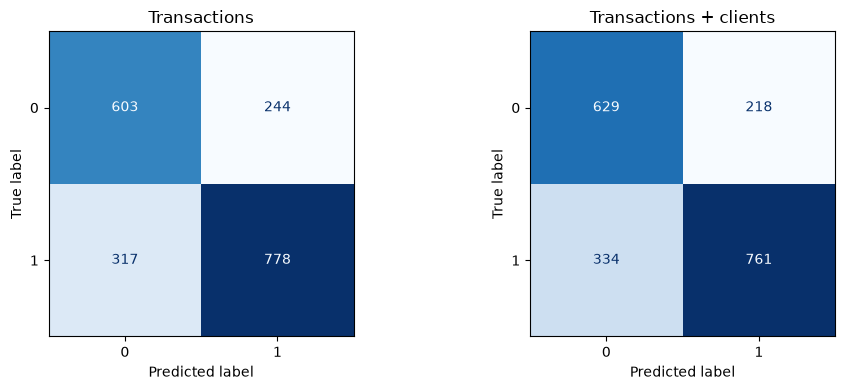

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, name in zip(axes, feature_sets):
    ConfusionMatrixDisplay.from_predictions(
        y_valid, selected_predictions[name], labels=[0, 1],
        ax=axis, cmap='Blues', colorbar=False
    )
    axis.set_title(name)
    tn, fp, fn, tp = confusion_matrix(
        y_valid, selected_predictions[name], labels=[0, 1]
    ).ravel()
    print(name + ':', int(fp), 'false positives;', int(fn), 'false negatives.')
plt.tight_layout()
plt.show()

**Interpretation:** compare false positives and false negatives with precision and recall. The prediction threshold stays at 0.5. Without commercial costs, we cannot declare this the best business threshold.

<a id="312-refit-the-selected-procedure-and-predict-test"></a>

## <font color="#0a65c7">3.12 Refit the Selected Procedure and Predict Test</font>

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

Refit the complete chosen pipeline on all 6,469 eligible labelled purchases, including the old gap and validation purchases. Their 90-day target windows end before test starts. Keep the chosen C, noise decision and threshold fixed.

Preprocessing, the L1 selector when applicable, and the final classifier are all refitted. The selected encoded-column list can therefore change: the exported final list below is the one actually used for test predictions. Test is transformed and predicted only; no stage is fitted on test.

In [18]:
first_test_date = pd.to_datetime(test['purchase_date'], errors='coerce').min()
assert data['purchase_date'].max() + pd.Timedelta(days=90) < first_test_date
if selected_version == 'Transactions + clients':
    final_frame, test_frame = data_clients, test_clients
else:
    final_frame, test_frame = data, test_clean
columns = feature_sets[selected_version]['train'].columns.tolist()
if not selected_settings['Keep noise']:
    columns.remove('random_noise')
X_final, X_test = final_frame[columns], test_frame[columns]
final_model = make_model(X_final, selected_settings['C'])
final_model.fit(X_final, data[TARGET])
test_probability = final_model.predict_proba(X_test)[:, 1]
test_prediction = (test_probability >= THRESHOLD).astype(int)

# Show only the retained columns, with their original variables and coefficients.
feature_rows = []
for name, coefficient in zip(selected_columns(final_model), final_model['classifier'].coef_[0]):
    raw = name.removeprefix('numeric__').removeprefix('missingindicator_')
    if name.startswith('categorical__'):
        matches = [col for col in columns if name.startswith('categorical__' + col + '_')]
        raw = max(matches, key=len)
    feature_rows.append([raw, name, coefficient])
final_features = pd.DataFrame(feature_rows, columns=['Original variable', 'Encoded column', 'Coefficient'])
display(final_features.style.set_properties(
    **{'white-space': 'normal', 'max-width': '400px', 'text-align': 'left'}
))
print('Final training purchases:', len(X_final))
print('Retained encoded columns:', len(final_features))
print('Original variables represented:', final_features['Original variable'].nunique())
print('Test predictions:', len(test_prediction))

,Original variable,Encoded column,Coefficient
0,Total Imp_,numeric__Total Imp_,0.088705
1,Total Desc_ Linha,numeric__Total Desc_ Linha,0.173187
2,prior_purchase_count,numeric__prior_purchase_count,0.195362
3,prior_max_purchase_value,numeric__prior_max_purchase_value,0.112775
4,prior_mean_gap_days,numeric__prior_mean_gap_days,-0.092994
5,purchase_count_90d,numeric__purchase_count_90d,0.883059
6,purchase_count_365d,numeric__purchase_count_365d,1.757916
7,spend_365d,numeric__spend_365d,0.057865
8,prior_std_purchase_value,numeric__missingindicator_prior_std_purchase_value,0.018158
9,prior_std_gap_days,numeric__missingindicator_prior_std_gap_days,0.083999


Final training purchases: 6469
Retained encoded columns: 12
Original variables represented: 12
Test predictions: 986


**Final feature-set justification:** the raw input set and the selection setting follow the recorded inner/main comparison; the fitted final subset is displayed above. Coefficients describe model associations, not causal effects. A categorical variable can contribute only some of its encoded categories. Refitting does not create a new validation score.

In [19]:
submission = sample[['ID']].copy()
submission[TARGET] = test_prediction
assert len(submission) == len(test) and submission['ID'].equals(test['ID'])
assert submission.columns.tolist() == sample.columns.tolist()
assert submission.notna().all().all() and submission[TARGET].isin([0, 1]).all()
submission_path = OUTPUT_DIR / 'submission_logistic_temporal.csv'
submission.to_csv(submission_path, index=False)
pd.testing.assert_frame_equal(pd.read_csv(submission_path), submission)

results.to_csv(OUTPUT_DIR / 'validation_metrics.csv')
inner_results.to_csv(OUTPUT_DIR / 'feature_selection_search.csv', index=False)
final_features.to_csv(OUTPUT_DIR / 'selected_features.csv', index=False)
display(submission.head())
print('Submission saved to:', submission_path)
print('CSV read-back check passed. No Kaggle upload was performed.')

# Machine-readable evidence keeps the two-page PDF aligned with this execution.
cleaning_audit.to_csv(OUTPUT_DIR / 'cleaning_audit.csv')
selected_names = selected_columns(final_model)
run_summary = {
    'versions': {'python': platform.python_version(), 'numpy': np.__version__,
                 'pandas': pd.__version__, 'sklearn': sklearn.__version__},
    'rows': {'raw_train': len(train), 'eligible_train': len(data), 'test': len(test),
             'raw_train_columns': len(train.columns), 'clients': len(clients),
             'client_columns': len(clients.columns)},
    'train_positive_rate': float(train[TARGET].mean()),
    'validation_positive_rate': float(y_valid.mean()),
    'split': {
        'train': int(training_rows.sum()), 'gap': int(gap_rows.sum()),
        'validation': int(validation_rows.sum()),
        'train_first': str(data.loc[training_rows, 'purchase_date'].min().date()),
        'train_last': str(data.loc[training_rows, 'purchase_date'].max().date()),
        'training_limit': str(training_limit.date()),
        'validation_first': str(validation_start.date()),
        'validation_last': str(data.loc[validation_rows, 'purchase_date'].max().date()),
        'test_first': str(first_test_date.date()),
        'test_last': str(pd.to_datetime(test['purchase_date']).max().date()),
    },
    'inner': {'train': int(inner_fit_rows.sum()), 'gap': int(inner_gap_rows.sum()),
              'validation': int(inner_valid_rows.sum()),
              'validation_first': str(inner_validation_start.date())},
    'baseline_metrics': baseline_results.reset_index().to_dict(orient='records'),
    'selected_metrics': results.reset_index().to_dict(orient='records'),
    'selected_version': selected_version,
    'selection': str(selected_settings['Selection']),
    'selector_C': None if pd.isna(selected_settings['C']) else float(selected_settings['C']),
    'keep_noise': bool(selected_settings['Keep noise']),
    'threshold': THRESHOLD,
    'final_encoded_before': len(final_model['preparation'].get_feature_names_out()),
    'final_encoded_retained': len(final_features),
    'final_raw_retained': int(final_features['Original variable'].nunique()),
    'final_raw_names': final_features['Original variable'].drop_duplicates().tolist(),
    'test_positive_predictions': int(test_prediction.sum()),
    'settings_by_feature_set': {
        name: {'selection': str(row['Selection']),
               'C': None if pd.isna(row['C']) else float(row['C']),
               'keep_noise': bool(row['Keep noise']),
               'inner_f1': float(row['Inner F1'])}
        for name, row in chosen_settings.iterrows()
    }
}
with (OUTPUT_DIR / 'report_summary.json').open('w', encoding='utf-8') as report_file:
    json.dump(run_summary, report_file, indent=2, allow_nan=False)
print('Cleaning audit and report summary saved.')

,ID,repeat_purchase_90d
0,10000006,1
1,10000008,1
2,10000010,1
3,10000020,0
4,10000025,0


Submission saved to: ..\outputs\notebook03\submission_logistic_temporal.csv
CSV read-back check passed. No Kaggle upload was performed.
Cleaning audit and report summary saved.


**Conclusion:** the submission has a binary prediction for every test ID in the required order. Six files are generated in `outputs/notebook03`: the submission, validation metrics, inner search, selected features, cleaning audit and a machine-readable report summary. The PDF is generated from that summary and the selected-feature table. Split summaries and paired noise comparisons are also visible above. No upload is performed.

<a id="313-limitations-and-next-steps"></a>

## <font color="#0a65c7">3.13 Limitations and Next Steps</font>

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

- Two feature sets, one classifier family and fixed 0.5 threshold are compared. There is no guarantee that client enrichment or selection improves generalisation.
- The small inner search uses one historical holdout. Its best score is selection evidence, not an unbiased performance estimate. Repeated temporal assessments could check stability in the final project.
- Main validation spans July 2022 to February 2025; an aggregate score can hide changes over time. The split was fixed before these selection experiments and was not moved to improve scores.
- Shared customers are intentional. This does not separately assess generalisation to entirely new customers.
- Client attributes are assumed historically available; excluding undated rows and treating totals/counts/minima/spread as trusted operands in the audited reconstruction rules are documented assumptions.
- EDA used target relationships across the supplied train data, and the final feature-set choice uses main validation. We acknowledge that the final score is not a completely untouched estimate.
- L1 can choose different members of a correlated group and individual one-hot columns. Selected variables are model-dependent, not a definitive account of business importance.
- The scope is a compact logistic-regression assessment with embedded selection. Broader algorithm comparisons and optimisation belong to the final project.
- Generated outputs should be regenerated and included as appropriate in the final submission package. The two-page pipeline PDF remains a separate deliverable.

**Class references:** `3_FeatureSelection.pdf` (embedded methods and L1); `week_04_feature_work_classification.ipynb` (Embedded methods); `week_05_model_selection.ipynb` (fit preprocessing inside selection folds and refit the chosen procedure). The classroom selection idea is adapted to this project's chronological data.

**Reading checklist:** explain both 90-day gaps, unchanged outer rows, inner versus outer validation, paired noise comparisons, encoded versus raw feature counts, the dummy reference, and why final refitting includes the old validation rows.